# ShopSphere Repurchase Prediction: Classical Machine Learning (LightGBM)
**Course:** IT2226 AI Innovation and Deep Learning Project  
**Target:** Customer Repurchase in October 2024 (`target = 1` vs `0`)  
**Database:** `shopsphere.db` (Relational SQLite schema with verified Foreign Keys)  
**Architecture:** Direct SQL feature extraction, class-imbalance reweighting, 5-Fold Stratified Cross-Validation, decision threshold tuning, and holdout inference.

## 1. Environment Setup & File Availability
Install LightGBM, upload `shopsphere.db` if running on Google Colab, and import analytical packages.

In [ ]:
# Install required packages
!pip install lightgbm scikit-learn matplotlib seaborn -q

import os
import time
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    f1_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix
)
import lightgbm as lgb

# Check for database file
DB_PATH = 'shopsphere.db'
if not os.path.exists(DB_PATH):
    print('Database shopsphere.db not found. Please upload it.')
    try:
        from google.colab import files
        uploaded = files.upload()
    except Exception as e:
        print('Not in Colab or upload skipped:', e)
else:
    size_mb = os.path.getsize(DB_PATH) / (1024 * 1024)
    print(f'Database detected: {DB_PATH} ({size_mb:.1f} MB)')

Database shopsphere.db not found. Please upload it.


Saving shopsphere.db to shopsphere.db


## 2. On-Demand SQL Customer 360 Feature Extraction
To eliminate row explosion and memory bloat, we aggregate child tables (transactions, sessions, deliveries, support tickets, and retention contact history) to the `customer_id` level directly inside SQLite before joining.

In [ ]:
t0 = time.time()
conn = sqlite3.connect(DB_PATH)

feature_query = '''
WITH cust_rfm AS (
    SELECT
        customer_id,
        COUNT(transaction_id) AS total_orders,
        COALESCE(SUM(order_value), 0.0) AS total_spend_usd,
        COALESCE(AVG(order_value), 0.0) AS avg_order_value,
        COALESCE(MAX(order_value), 0.0) AS max_order_value,
        COALESCE(SUM(items_count), 0) AS total_items_bought,
        COALESCE(SUM(discount_applied), 0) AS discounted_orders_count,
        COALESCE(SUM(high_value_flag), 0) AS high_value_orders_count,
        COALESCE(SUM(CASE WHEN transaction_timestamp >= '2024-09-01' THEN 1 ELSE 0 END), 0) AS orders_last_30d,
        COALESCE(SUM(CASE WHEN transaction_timestamp >= '2024-07-01' THEN 1 ELSE 0 END), 0) AS orders_last_90d,
        ROUND(JULIANDAY('2024-09-30') - JULIANDAY(MAX(transaction_timestamp)), 1) AS recency_days
    FROM transactions
    GROUP BY customer_id
),
cust_sessions AS (
    SELECT
        customer_id,
        COUNT(session_id) AS total_sessions,
        COALESCE(SUM(pages_viewed), 0) AS total_pages_viewed,
        COALESCE(SUM(cart_additions), 0) AS total_cart_additions,
        COALESCE(SUM(bounce_flag), 0) AS total_bounced_sessions,
        COALESCE(AVG(session_duration_capped), 0.0) AS avg_session_duration_s,
        COALESCE(SUM(CASE WHEN session_timestamp >= '2024-09-01' THEN 1 ELSE 0 END), 0) AS sessions_last_30d,
        COALESCE(SUM(CASE WHEN session_timestamp >= '2024-07-01' THEN 1 ELSE 0 END), 0) AS sessions_last_90d,
        ROUND(JULIANDAY('2024-09-30') - JULIANDAY(MAX(session_timestamp)), 1) AS days_since_last_session
    FROM sessions
    GROUP BY customer_id
),
cust_deliveries AS (
    SELECT
        t.customer_id,
        COUNT(d.transaction_id) AS total_deliveries,
        COALESCE(SUM(CASE WHEN d.delivery_status = 'Late' THEN 1 ELSE 0 END), 0) AS late_deliveries_count,
        COALESCE(SUM(CASE WHEN d.delivery_status = 'Lost' THEN 1 ELSE 0 END), 0) AS lost_packages_count,
        COALESCE(AVG(d.delay_days), 0.0) AS avg_delay_days
    FROM transactions t
    JOIN deliveries d ON t.transaction_id = d.transaction_id
    GROUP BY t.customer_id
),
cust_tickets AS (
    SELECT
        customer_id,
        COUNT(ticket_id) AS total_support_tickets,
        COALESCE(SUM(CASE WHEN status = 'Open' THEN 1 ELSE 0 END), 0) AS open_tickets_count,
        COALESCE(SUM(CASE WHEN status = 'Open' AND priority IN ('High', 'Urgent') THEN 1 ELSE 0 END), 0) AS high_priority_open_tickets,
        AVG(csat_score) AS avg_csat_score
    FROM support_tickets
    GROUP BY customer_id
),
cust_retention AS (
    SELECT
        customer_id,
        COUNT(contact_id) AS retention_contacts_count,
        COALESCE(SUM(redeemed), 0) AS retention_redeemed_count,
        COALESCE(SUM(purchased_within_14d), 0) AS retention_purchased_count
    FROM retention_contact_history
    GROUP BY customer_id
)
SELECT
    c.customer_id,
    c.age,
    c.age_is_missing,
    c.country_code,
    c.customer_tier,
    c.credit_limit,
    c.loyalty_score,
    c.email_open_rate,
    c.email_open_rate_is_missing,
    c.avg_review_score,
    ROUND(JULIANDAY('2024-09-30') - JULIANDAY(c.signup_date), 1) AS account_age_days,
    COALESCE(p.email_opt_in, 0) AS email_opt_in,
    COALESCE(p.sms_opt_in, 0) AS sms_opt_in,
    COALESCE(p.do_not_contact, 0) AS do_not_contact,
    COALESCE(p.preferred_channel, 'unknown') AS preferred_channel,
    COALESCE(rfm.total_orders, 0) AS total_orders,
    COALESCE(rfm.total_spend_usd, 0.0) AS total_spend_usd,
    COALESCE(rfm.avg_order_value, 0.0) AS avg_order_value,
    COALESCE(rfm.max_order_value, 0.0) AS max_order_value,
    COALESCE(rfm.total_items_bought, 0) AS total_items_bought,
    COALESCE(rfm.discounted_orders_count, 0) AS discounted_orders_count,
    COALESCE(rfm.high_value_orders_count, 0) AS high_value_orders_count,
    COALESCE(rfm.orders_last_30d, 0) AS orders_last_30d,
    COALESCE(rfm.orders_last_90d, 0) AS orders_last_90d,
    rfm.recency_days,
    COALESCE(s.total_sessions, 0) AS total_sessions,
    COALESCE(s.total_pages_viewed, 0) AS total_pages_viewed,
    COALESCE(s.total_cart_additions, 0) AS total_cart_additions,
    COALESCE(s.total_bounced_sessions, 0) AS total_bounced_sessions,
    COALESCE(s.avg_session_duration_s, 0.0) AS avg_session_duration_s,
    COALESCE(s.sessions_last_30d, 0) AS sessions_last_30d,
    COALESCE(s.sessions_last_90d, 0) AS sessions_last_90d,
    s.days_since_last_session,
    COALESCE(d.total_deliveries, 0) AS total_deliveries,
    COALESCE(d.late_deliveries_count, 0) AS late_deliveries_count,
    COALESCE(d.lost_packages_count, 0) AS lost_packages_count,
    COALESCE(d.avg_delay_days, 0.0) AS avg_delay_days,
    COALESCE(t.total_support_tickets, 0) AS total_support_tickets,
    COALESCE(t.open_tickets_count, 0) AS open_tickets_count,
    COALESCE(t.high_priority_open_tickets, 0) AS high_priority_open_tickets,
    t.avg_csat_score,
    COALESCE(r.retention_contacts_count, 0) AS retention_contacts_count,
    COALESCE(r.retention_redeemed_count, 0) AS retention_redeemed_count,
    COALESCE(r.retention_purchased_count, 0) AS retention_purchased_count,
    tr.target,
    CASE WHEN te.customer_id IS NOT NULL THEN 1 ELSE 0 END AS is_test
FROM customers c
LEFT JOIN customer_preferences p ON c.customer_id = p.customer_id
LEFT JOIN cust_rfm rfm ON c.customer_id = rfm.customer_id
LEFT JOIN cust_sessions s ON c.customer_id = s.customer_id
LEFT JOIN cust_deliveries d ON c.customer_id = d.customer_id
LEFT JOIN cust_tickets t ON c.customer_id = t.customer_id
LEFT JOIN cust_retention r ON c.customer_id = r.customer_id
LEFT JOIN train tr ON c.customer_id = tr.customer_id
LEFT JOIN test te ON c.customer_id = te.customer_id;
'''

df = pd.read_sql_query(feature_query, conn)
conn.close()
print(f'Extracted {len(df):,} customer records in {time.time() - t0:.2f} seconds.')
df.head()

Extracted 80,000 customer records in 8.67 seconds.


,customer_id,age,age_is_missing,country_code,customer_tier,credit_limit,loyalty_score,email_open_rate,email_open_rate_is_missing,avg_review_score,...,avg_delay_days,total_support_tickets,open_tickets_count,high_priority_open_tickets,avg_csat_score,retention_contacts_count,retention_redeemed_count,retention_purchased_count,target,is_test
0,0,51.0,0,DE,Bronze,17757.0,0.248,0.234475,0,4.21,...,0.0,0,0,0,NaN,1,0,0,0.0,0
1,1,39.0,0,US,Bronze,3424.0,0.077,0.610079,0,3.87,...,0.0,0,0,0,NaN,0,0,0,0.0,0
2,2,56.0,0,UK,Bronze,13373.0,0.160,0.466131,0,4.74,...,0.0,0,0,0,NaN,1,0,0,NaN,1
3,3,29.0,0,UK,Silver,18995.0,0.163,0.482747,0,4.07,...,0.0,0,0,0,NaN,0,0,0,NaN,1
4,4,44.0,0,FR,Bronze,11074.0,0.133,0.206030,0,3.34,...,0.0,1,0,0,NaN,0,0,0,0.0,0


## 3. Behavioral Feature Engineering & Type Casting
We compute key behavioral ratios: cart abandonment rate, discount reliance, bounce rate, and inactivity flags.

In [ ]:
# Derived domain ratios
df['discount_order_ratio'] = np.where(df['total_orders'] > 0, df['discounted_orders_count'] / df['total_orders'], 0.0)
df['bounce_rate'] = np.where(df['total_sessions'] > 0, df['total_bounced_sessions'] / df['total_sessions'], 0.0)
df['cart_abandonment_ratio'] = np.where(
    df['total_cart_additions'] > 0,
    np.clip(1.0 - (df['total_orders'] / df['total_cart_additions']), 0.0, 1.0),
    0.0
)
df['is_inactive_90d'] = ((df['orders_last_90d'] == 0) & (df['sessions_last_90d'] == 0)).astype(int)

# Set categorical dtypes for LightGBM optimal branching
CATEGORICAL_COLS = ['country_code', 'customer_tier', 'preferred_channel']
for col in CATEGORICAL_COLS:
    df[col] = df[col].astype('category')

EXCLUDE_COLS = ['customer_id', 'target', 'is_test']
FEATURE_COLS = [c for c in df.columns if c not in EXCLUDE_COLS]

train_df = df[df['is_test'] == 0].copy()
test_df = df[df['is_test'] == 1].copy()

X = train_df[FEATURE_COLS]
y = train_df['target'].astype(int)
X_test = test_df[FEATURE_COLS]

print(f'Engineered features: {len(FEATURE_COLS)}')
print(f'Train customers: {len(X):,} | Repurchase Rate: {y.mean():.2%}')
print(f'Holdout test customers: {len(X_test):,}')

Engineered features: 47
Train customers: 64,000 | Repurchase Rate: 14.57%
Holdout test customers: 16,000


## 4. LightGBM 5-Fold Stratified Cross-Validation
We set `scale_pos_weight` to address the ~1:5.8 imbalanced target distribution and run 5-Fold Stratified CV with early stopping.

In [ ]:
scale_pos_weight = (len(y) - y.sum()) / y.sum()

params = {
    'objective': 'binary',
    'metric': ['auc', 'binary_logloss'],
    'boosting_type': 'gbdt',
    'learning_rate': 0.03,
    'num_leaves': 31,
    'max_depth': -1,
    'min_child_samples': 30,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'scale_pos_weight': scale_pos_weight,
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = np.zeros(len(train_df))
test_preds = np.zeros(len(test_df))
feature_importances = np.zeros(len(FEATURE_COLS))

print('=' * 65)
print('STARTING 5-FOLD STRATIFIED CROSS-VALIDATION')
print('=' * 65)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    trn_data = lgb.Dataset(X_tr, label=y_tr, categorical_feature=CATEGORICAL_COLS)
    val_data = lgb.Dataset(X_va, label=y_va, reference=trn_data, categorical_feature=CATEGORICAL_COLS)

    model = lgb.train(
        params,
        trn_data,
        num_boost_round=1200,
        valid_sets=[trn_data, val_data],
        valid_names=['train', 'val'],
        callbacks=[
            lgb.early_stopping(stopping_rounds=50, verbose=False),
            lgb.log_evaluation(period=0)
        ]
    )

    val_pred = model.predict(X_va, num_iteration=model.best_iteration)
    oof_preds[val_idx] = val_pred

    test_preds += model.predict(X_test, num_iteration=model.best_iteration) / skf.n_splits
    feature_importances += model.feature_importance(importance_type='gain') / skf.n_splits

    fold_auc = roc_auc_score(y_va, val_pred)
    fold_pr_auc = average_precision_score(y_va, val_pred)
    print(f'Fold {fold} | Best Iteration: {model.best_iteration:4d} | ROC-AUC: {fold_auc:.5f} | PR-AUC: {fold_pr_auc:.5f}')

STARTING 5-FOLD STRATIFIED CROSS-VALIDATION
Fold 1 | Best Iteration:   19 | ROC-AUC: 0.87473 | PR-AUC: 0.56206
Fold 2 | Best Iteration:   18 | ROC-AUC: 0.86788 | PR-AUC: 0.54023
Fold 3 | Best Iteration:   17 | ROC-AUC: 0.87201 | PR-AUC: 0.55552
Fold 4 | Best Iteration:   17 | ROC-AUC: 0.87094 | PR-AUC: 0.55539
Fold 5 | Best Iteration:   17 | ROC-AUC: 0.86835 | PR-AUC: 0.54087


## 5. Out-Of-Fold Evaluation & Threshold Tuning
We evaluate Out-Of-Fold discrimination and sweep thresholds to optimize the F1-Score.

In [ ]:
overall_auc = roc_auc_score(y, oof_preds)
overall_pr_auc = average_precision_score(y, oof_preds)

print('=' * 50)
print(f'Overall OOF ROC-AUC : {overall_auc:.5f}')
print(f'Overall OOF PR-AUC  : {overall_pr_auc:.5f}')
print('=' * 50)

# Threshold sweep
best_thresh = 0.5
best_f1 = 0.0
thresholds = np.arange(0.30, 0.70, 0.02)
for t in thresholds:
    score = f1_score(y, (oof_preds >= t).astype(int))
    if score > best_f1:
        best_f1 = score
        best_thresh = t

print(f'Optimal Decision Threshold: {best_thresh:.2f} (Max F1 = {best_f1:.4f})')
print('\nClassification Report at Optimal Threshold:')
print(classification_report(y, (oof_preds >= best_thresh).astype(int), digits=4))

Overall OOF ROC-AUC : 0.87025
Overall OOF PR-AUC  : 0.54194
Optimal Decision Threshold: 0.38 (Max F1 = 0.5362)

Classification Report at Optimal Threshold:
              precision    recall  f1-score   support

           0     0.9277    0.8956    0.9114     54674
           1     0.4911    0.5905    0.5362      9326

    accuracy                         0.8512     64000
   macro avg     0.7094    0.7431    0.7238     64000
weighted avg     0.8640    0.8512    0.8567     64000



## 6. Visual Diagnostics & Feature Importance
Plotting ROC Curve, Precision-Recall Curve, and ranking the top predictive drivers.

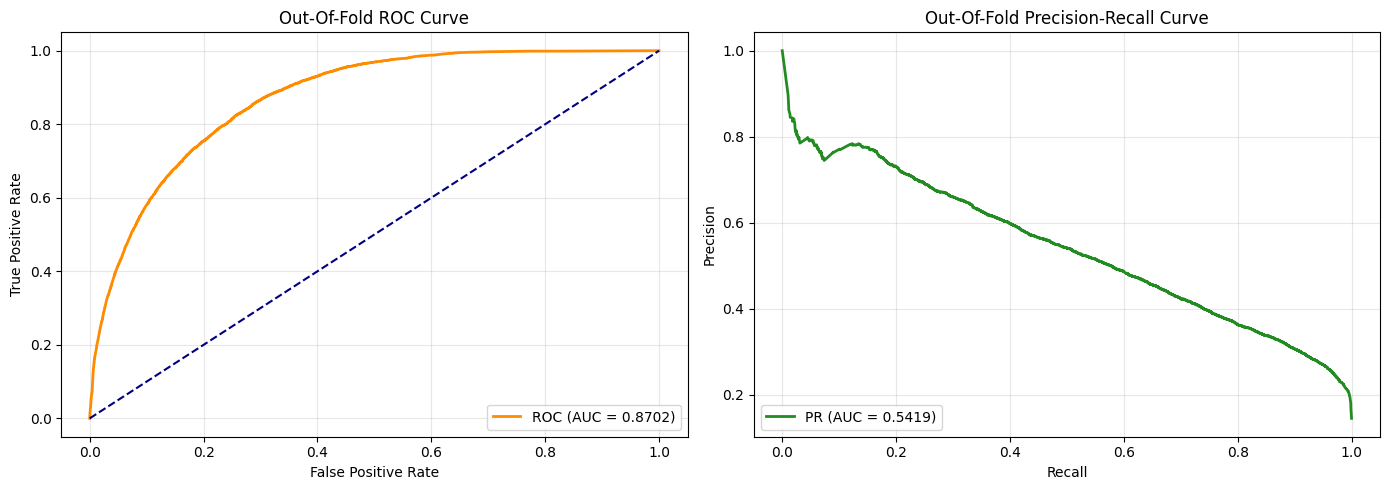

/tmp/ipykernel_2038/1920662321.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df.head(15), x='gain', y='feature', palette='viridis')


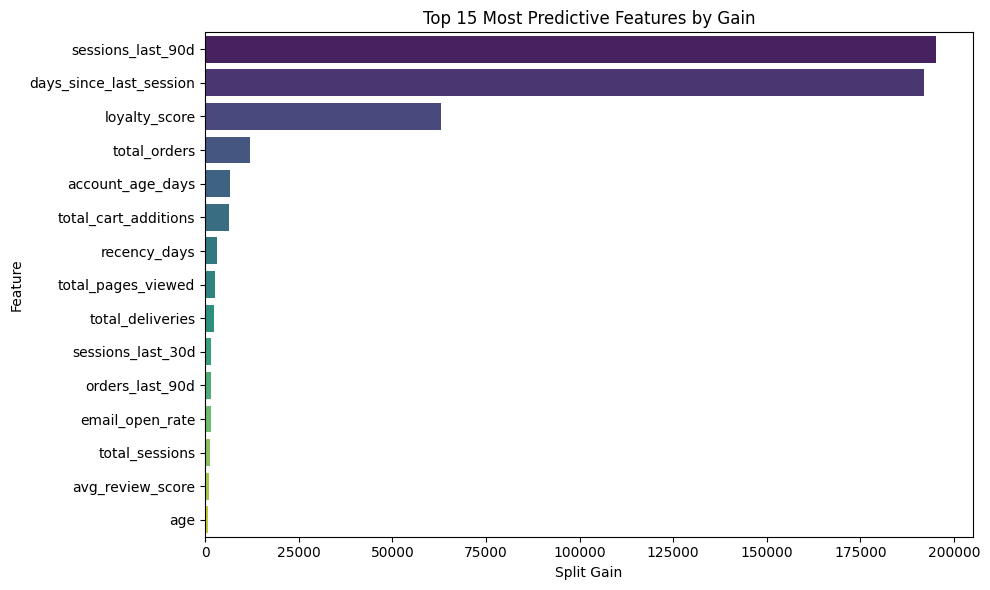

                feature          gain
      sessions_last_90d 195211.074931
days_since_last_session 192069.199858
          loyalty_score  62874.503255
           total_orders  11865.980471
       account_age_days   6720.098306
   total_cart_additions   6313.366212
           recency_days   3290.354028
     total_pages_viewed   2561.119382
       total_deliveries   2405.413342
      sessions_last_30d   1664.670639


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
fpr, tpr, _ = roc_curve(y, oof_preds)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {overall_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
axes[0].set_title('Out-Of-Fold ROC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y, oof_preds)
axes[1].plot(rec, prec, color='forestgreen', lw=2, label=f'PR (AUC = {overall_pr_auc:.4f})')
axes[1].set_title('Out-Of-Fold Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Feature Importance Plot
fi_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'gain': feature_importances
}).sort_values(by='gain', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=fi_df.head(15), x='gain', y='feature', palette='viridis')
plt.title('Top 15 Most Predictive Features by Gain')
plt.xlabel('Split Gain')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print(fi_df.head(10).to_string(index=False))

## 7. Submission Export & Download
Export holdout customer predictions formatted to match `sample_submission.csv`.

In [ ]:
sub_df = pd.DataFrame({
    'customer_id': test_df['customer_id'].astype(int),
    'target': (test_preds >= best_thresh).astype(int)
})

sub_path = 'submission_lightgbm.csv'
sub_df.to_csv(sub_path, index=False)
print(f'Submission saved to {sub_path}')
print(f'Predicted repurchase rate: {sub_df["target"].mean():.2%} ({sub_df["target"].sum():,} / {len(sub_df):,})')

# Auto download if running in Google Colab
# try:
#     from google.colab import files
#     files.download(sub_path)
# except Exception:
#     pass

Submission saved to submission_lightgbm.csv
Predicted repurchase rate: 17.15% (2,744 / 16,000)


In [ ]:
def test_customer(customer_id):
        cust_row = df[df['customer_id'] == customer_id]
        if cust_row.empty:
            print(f"Customer {customer_id} not found in database.")
            return

        features = cust_row[FEATURE_COLS]
        prob = float(model.predict(features)[0])
        is_repurchase = prob >= best_thresh

        # Business Strategy Categorization
        if prob >= 0.70:
            segment = 'Organic Buyer (High Loyalty)'
            action = 'DO NOT DISCOUNT. Customer will buy organically; save marketing margin.'
        elif prob >= best_thresh:
            segment = 'Persuadable Lead (Ideal Target)'
            action = 'SEND RETENTION OFFER (e.g. 10% voucher / free gift) to guarantee conversion.'
        elif prob >= 0.15:
            segment = 'At-Risk Customer'
            action = 'Engage with low-cost channel (Email/SMS newsletter or top trending products).'
        else:
            segment = 'Dormant / Lost'
            action = 'Check support tickets for past bad experiences or suppress from budget.'

        tier = cust_row['customer_tier'].values[0]
        country = cust_row['country_code'].values[0]
        loyalty = cust_row['loyalty_score'].values[0]
        spend = cust_row['total_spend_usd'].values[0]
        orders = int(cust_row['total_orders'].values[0])
        days_visit = cust_row['days_since_last_session'].values[0]
        sess_90d = int(cust_row['sessions_last_90d'].values[0])
        tickets = int(cust_row['open_tickets_count'].values[0])
        deliv = int(cust_row['late_deliveries_count'].values[0])

        print("=" * 65)
        print(f"CUSTOMER 360 PREDICTION: ID {customer_id}")
        print("=" * 65)
        print(f"Tier: {tier} | Country: {country} | Loyalty Score: {loyalty:.2f}")
        print(f"Total Spend: ${spend:,.2f} across {orders} orders")
        print(f"Days Since Last Visit: {days_visit} | Sessions (90d): {sess_90d}")
        print(f"Open Tickets: {tickets} | Late Deliveries: {deliv}")
        print("-" * 65)
        print(f"Predicted Repurchase Probability : {prob * 100:.2f}%")
        print(f"Model Classification Decision    : {'BUY (1)' if is_repurchase else 'NO BUY (0)'}")
        print(f"Targeting Segment               : {segment}")
        print(f"Recommended Action              : {action}")
        print("=" * 65)

# Test customer

test_customer(10126)


CUSTOMER 360 PREDICTION: ID 10126
Tier: Silver | Country: US | Loyalty Score: 0.17
Total Spend: $278.33 across 5 orders
Days Since Last Visit: 189.0 | Sessions (90d): 0
Open Tickets: 0 | Late Deliveries: 0
-----------------------------------------------------------------
Predicted Repurchase Probability : 10.35%
Model Classification Decision    : NO BUY (0)
Targeting Segment               : Dormant / Lost
Recommended Action              : Check support tickets for past bad experiences or suppress from budget.


Benchmark Bar to Beat:
      
      • ROC-AUC = 0.87025
      • PR-AUC = 0.54194
      Model Type: Gradient Boosted Decision tree
      Features used: 47 engineered features from the db file
      Validation used: 5-fold stratified cross validation with cutoff date of 2024/09/30

In [ ]:
import sqlite3
import pandas as pd

DB_PATH = 'shopsphere.db'   # on Colab, upload it first (cell 2 does this)
conn = sqlite3.connect(f'file:{DB_PATH}?mode=ro', uri=True)

def q(sql):
    """Run a query and return the result as a DataFrame."""
    return pd.read_sql_query(sql, conn)

# A: is 'Late' a real delivery status?
print('A. Delivery statuses')
display(q("SELECT delivery_status, COUNT(*) AS n FROM deliveries GROUP BY 1 ORDER BY 2 DESC"))

# B: do late-September contacts encode October purchases?
print('B. Contacts after 16 Sep')
display(q("""
SELECT COUNT(*) AS contacts,
       SUM(purchased_within_14d) AS flagged_purchase,
       SUM(CASE WHEN purchased_within_14d = 1 AND NOT EXISTS (
               SELECT 1 FROM transactions t
               WHERE t.customer_id = r.customer_id
                 AND t.transaction_timestamp BETWEEN r.contact_date AND '2024-09-30')
           THEN 1 ELSE 0 END) AS october_only,
       SUM(CASE WHEN redemption_date > '2024-09-30' THEN 1 ELSE 0 END) AS redeemed_in_october
FROM retention_contact_history r
WHERE contact_date > '2024-09-16'
"""))

# C: deliveries resolved after the cutoff (settles the 510 discrepancy)
print('C. Deliveries resolved after 30 Sep')
display(q("""
SELECT COUNT(*) AS delivered_after_cutoff,
       SUM(CASE WHEN ship_date <= '2024-09-30' THEN 1 ELSE 0 END) AS shipped_before_cutoff
FROM deliveries WHERE delivered_date > '2024-09-30'
"""))

# D: hint for the submission format (labels or probabilities?)
print('D. sample_submission placeholder values')
display(q("SELECT target, COUNT(*) AS n FROM sample_submission GROUP BY 1 LIMIT 10"))

conn.close()

A. Delivery statuses


,delivery_status,n
0,Delivered,260124
1,Delivered Late,26799
2,Returned,9400
3,In Transit,3222
4,Lost,1698


B. Contacts after 16 Sep


,contacts,flagged_purchase,october_only,redeemed_in_october
0,1419,91,0,0


C. Deliveries resolved after 30 Sep


,delivered_after_cutoff,shipped_before_cutoff
0,0,None


D. sample_submission placeholder values


,target,n
0,0,16000
